# Yapay Zekâ İşleri mi Alıyor, Yoksa Sadece Suçu mu Üstleniyor?

Medium makalesindeki tüm grafik ve rakamları üreten notebook.

**Veri:** Bitirme projemin temizlenmiş ve doğrulanmış dosyaları — [Uguravsar75/ai-layoffs-vs-hiring-2026](https://github.com/Uguravsar75/ai-layoffs-vs-hiring-2026) (`data/clean/`):
- layoffhedge.com 2026 işten çıkarma listesi (8 Kasım 2026 sürümü), 146 satır elle doğrulanmış
- Challenger, Gray & Christmas aylık ABD raporları (bağımsız karşılaştırma)
- Indeed Hiring Lab AI Tracker (CC BY 4.0)

**Makale:** Medium linki README’de.

## Kurulum

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from scipy.stats import mannwhitneyu

OUT = Path("gorseller")
OUT.mkdir(exist_ok=True)
REPO = "https://raw.githubusercontent.com/Uguravsar75/ai-layoffs-vs-hiring-2026/main/data/clean/"


def oku(ad):
    return pd.read_csv(REPO + ad)


# ---------- Görsel stil (seride ortak) ----------
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
LIGHT = "#c9c6bd"
AYLAR = {1: "Oca", 2: "Şub", 3: "Mar", 4: "Nis", 5: "May", 6: "Haz", 7: "Tem",
         8: "Ağu", 9: "Eyl", 10: "Eki", 11: "Kas", 12: "Ara"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
})
YUZDE = FuncFormatter(lambda v, _: f"%{v:g}".replace(".", ","))


def save(fig, name):
    fig.savefig(OUT / name, dpi=200, bbox_inches="tight", pad_inches=0.35)
    plt.show()


def y1(x):
    return f"{x:.1f}".replace(".", ",")


def binlik(n):
    return f"{int(n):,}".replace(",", ".")


def ay_etiket(m):  # "2026-05" -> "May\n2026" sadece Ocak'ta yıl
    y, a = m.split("-")
    a = int(a)
    return AYLAR[a] + (f"\n{y}" if a == 1 or m == "2025-09" else "")


## 0. Veri ve manşet rakamları
Ana analiz, dar/geniş AI tanımı, medyan karşılaştırması (bootstrap + Mann-Whitney) ve elle doğrulama kapsamı.

In [2]:
d = oku("layoffs_clean.csv")
m = d[d["in_main_analysis"]].copy()
P = m["people_cut"].sum()
dar = m[m["is_ai_strict"]]
genis = m[m["is_ai_driven"]]
ai_degil = m[~m["is_ai_driven"]]

print(f"Ana analiz: {len(m)} duyuru, {binlik(P)} kişi (toplam satır {len(d)}, geçersiz {int(d.is_invalid.sum())})")
print(f"AI kişi payı: dar %{dar.people_cut.sum() / P * 100:.1f} | geniş %{genis.people_cut.sum() / P * 100:.1f}")
print(f"AI duyuru payı (dar): %{len(dar) / len(m) * 100:.1f}  (dar n={len(dar)}, geniş n={len(genis)})")
p_mw = mannwhitneyu(dar.people_cut, ai_degil.people_cut, alternative="greater").pvalue
print(f"Medyan: AI (dar) {dar.people_cut.median():.0f} (n={len(dar)}) vs AI olmayan {ai_degil.people_cut.median():.0f} "
      f"(n={len(ai_degil)}) | Mann-Whitney p={p_mw:.5f}")

ust3 = m["reliability_tier"].str[:2].isin(["T1", "T2", "T3"])
elle_dogrulanan = m["reliability_tier"].str[:2].isin(["T1", "T2"])
print(f"Elle kontrol edilen satır: {int((d.verification != 'not_checked').sum())} | "
      f"doğrulanan (T1–T2): {int(elle_dogrulanan.sum())} satır, kişilerin %{m.loc[elle_dogrulanan, 'people_cut'].sum() / P * 100:.1f}'i | "
      f"T1–T3: kişilerin %{m.loc[ust3, 'people_cut'].sum() / P * 100:.1f}'i")


Ana analiz: 643 duyuru, 653.456 kişi (toplam satır 653, geçersiz 4)
AI kişi payı: dar %16.9 | geniş %38.4
AI duyuru payı (dar): %11.5  (dar n=74, geniş n=92)
Medyan: AI (dar) 295 (n=74) vs AI olmayan 180 (n=551) | Mann-Whitney p=0.00009
Elle kontrol edilen satır: 146 | doğrulanan (T1–T2): 133 satır, kişilerin %72.3'i | T1–T3: kişilerin %81.6'i


## 1. En büyük 10 “AI” etiketli duyuru
Haber kaynaklarıyla karşılaştırma sonrası: dar tanım, şüpheli etiket veya “en fazla” (üst sınır) rakam.

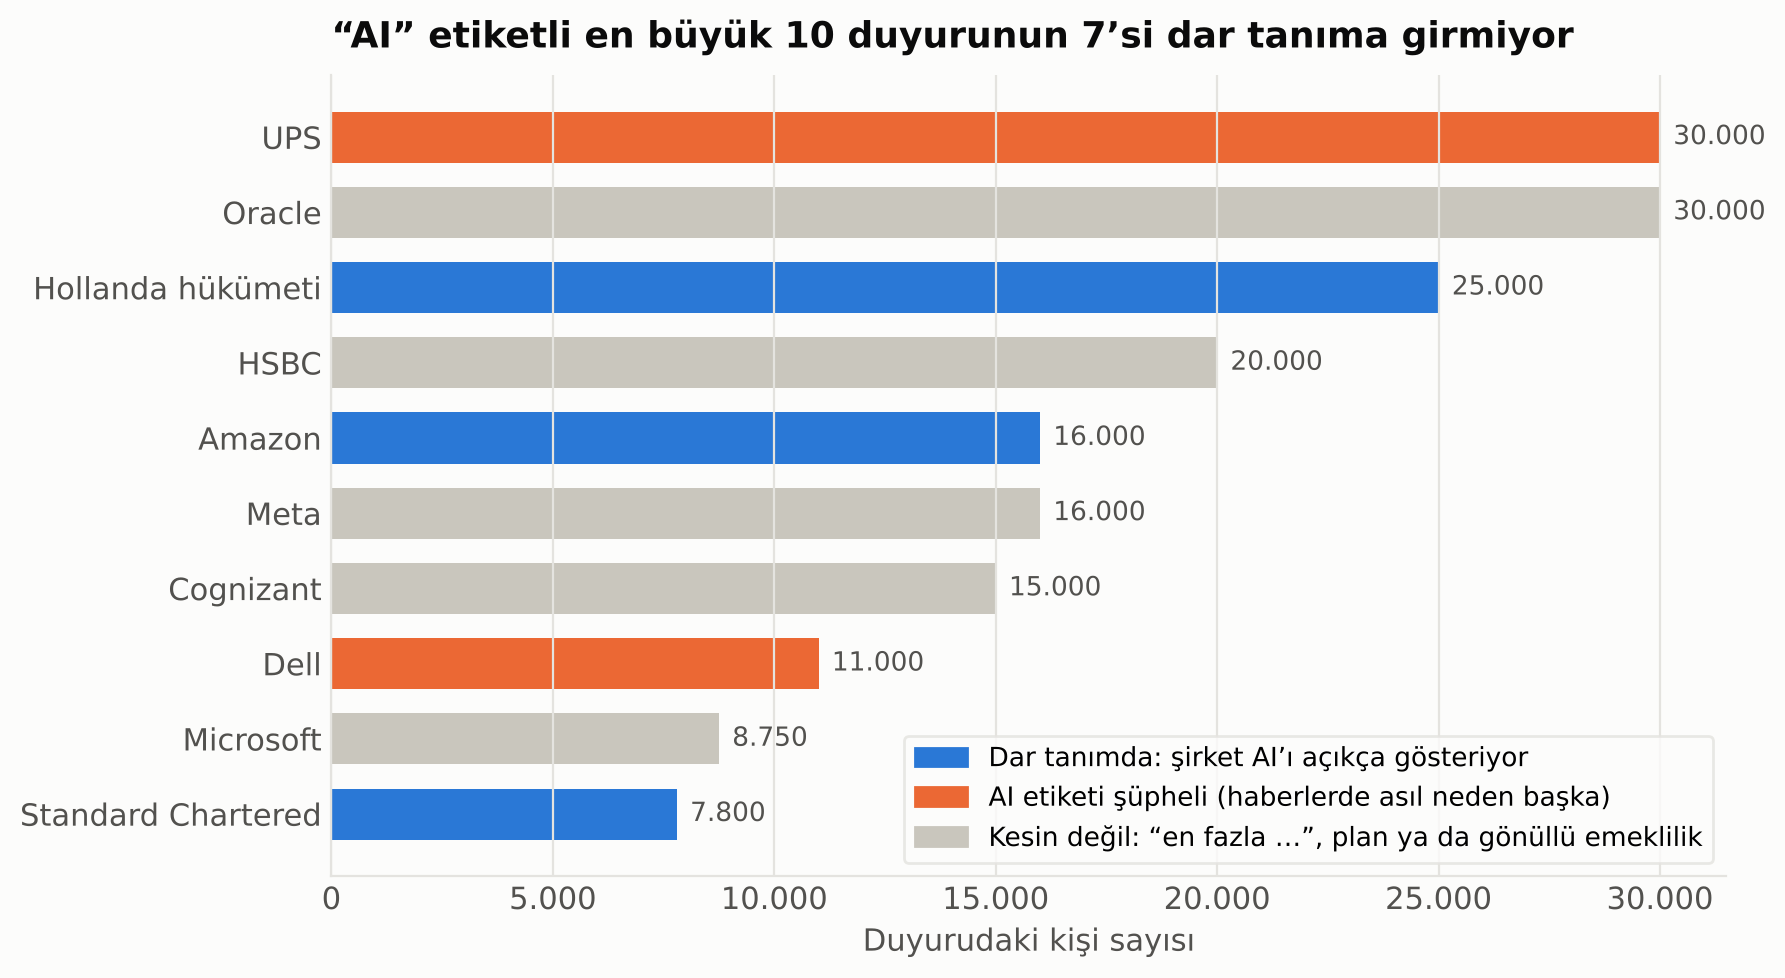


[Grafik 1] en büyük 10 AI etiketli duyuru: dar=3, şüpheli=2, üst sınır=5


In [3]:
t = genis.sort_values("people_cut", ascending=False).head(10).iloc[::-1]
durum = np.where(t["is_ai_strict"], "dar",
                 np.where(t["ai_label_questionable"], "supheli", "ust"))
renk = {"dar": BLUE, "supheli": ORANGE, "ust": LIGHT}
etiket = {"dar": "Dar tanımda: şirket AI’ı açıkça gösteriyor",
          "supheli": "AI etiketi şüpheli (haberlerde asıl neden başka)",
          "ust": "Kesin değil: “en fazla …”, plan ya da gönüllü emeklilik"}
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(np.arange(len(t)), t["people_cut"], color=[renk[x] for x in durum], height=0.68)
ax.set_yticks(np.arange(len(t))); ax.set_yticklabels(t["company"].replace({"Dutch Government": "Hollanda hükümeti"}))
for i, v in enumerate(t["people_cut"]):
    ax.text(v + 300, i, binlik(v), va="center", fontsize=9.5, color=INK_2)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: binlik(v)))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Duyurudaki kişi sayısı")
ax.legend(handles=[Patch(color=renk[k], label=etiket[k]) for k in ["dar", "supheli", "ust"]],
          loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, fontsize=9.5)
n_dar = int((durum == "dar").sum())
ax.set_title(f"“AI” etiketli en büyük {len(t)} duyurunun {len(t) - n_dar}’si dar tanıma girmiyor", pad=10)
save(fig, "01_buyuk_ai_duyurulari.png")
print(f"\n[Grafik 1] en büyük {len(t)} AI etiketli duyuru: dar={n_dar}, şüpheli={int((durum == 'supheli').sum())}, "
      f"üst sınır={int((durum == 'ust').sum())}")


## 2. Aylık AI payı ve Challenger karşılaştırması
Üst panel duyuru payı, alt panel kişi payı. Not: Korelasyon farklı ölçüler arasındadır (duyuru payı ve Challenger kişi payı).


[Grafik 2] aylık AI duyuru payı (dar): {'2026-01': 19.2, '2026-02': 15.0, '2026-03': 8.5, '2026-04': 15.6, '2026-05': 40.3, '2026-06': 20.0, '2026-07': 17.6, '2026-08': 2.8, '2026-09': 2.8, '2026-10': 5.3}
           aylık AI kişi payı (dar):   {'2026-01': 30.0, '2026-02': 35.9, '2026-03': 1.5, '2026-04': 5.4, '2026-05': 37.0, '2026-06': 3.8, '2026-07': 15.0, '2026-08': 1.2, '2026-09': 0.7, '2026-10': 50.5}
           Challenger ile korelasyon: 0.72


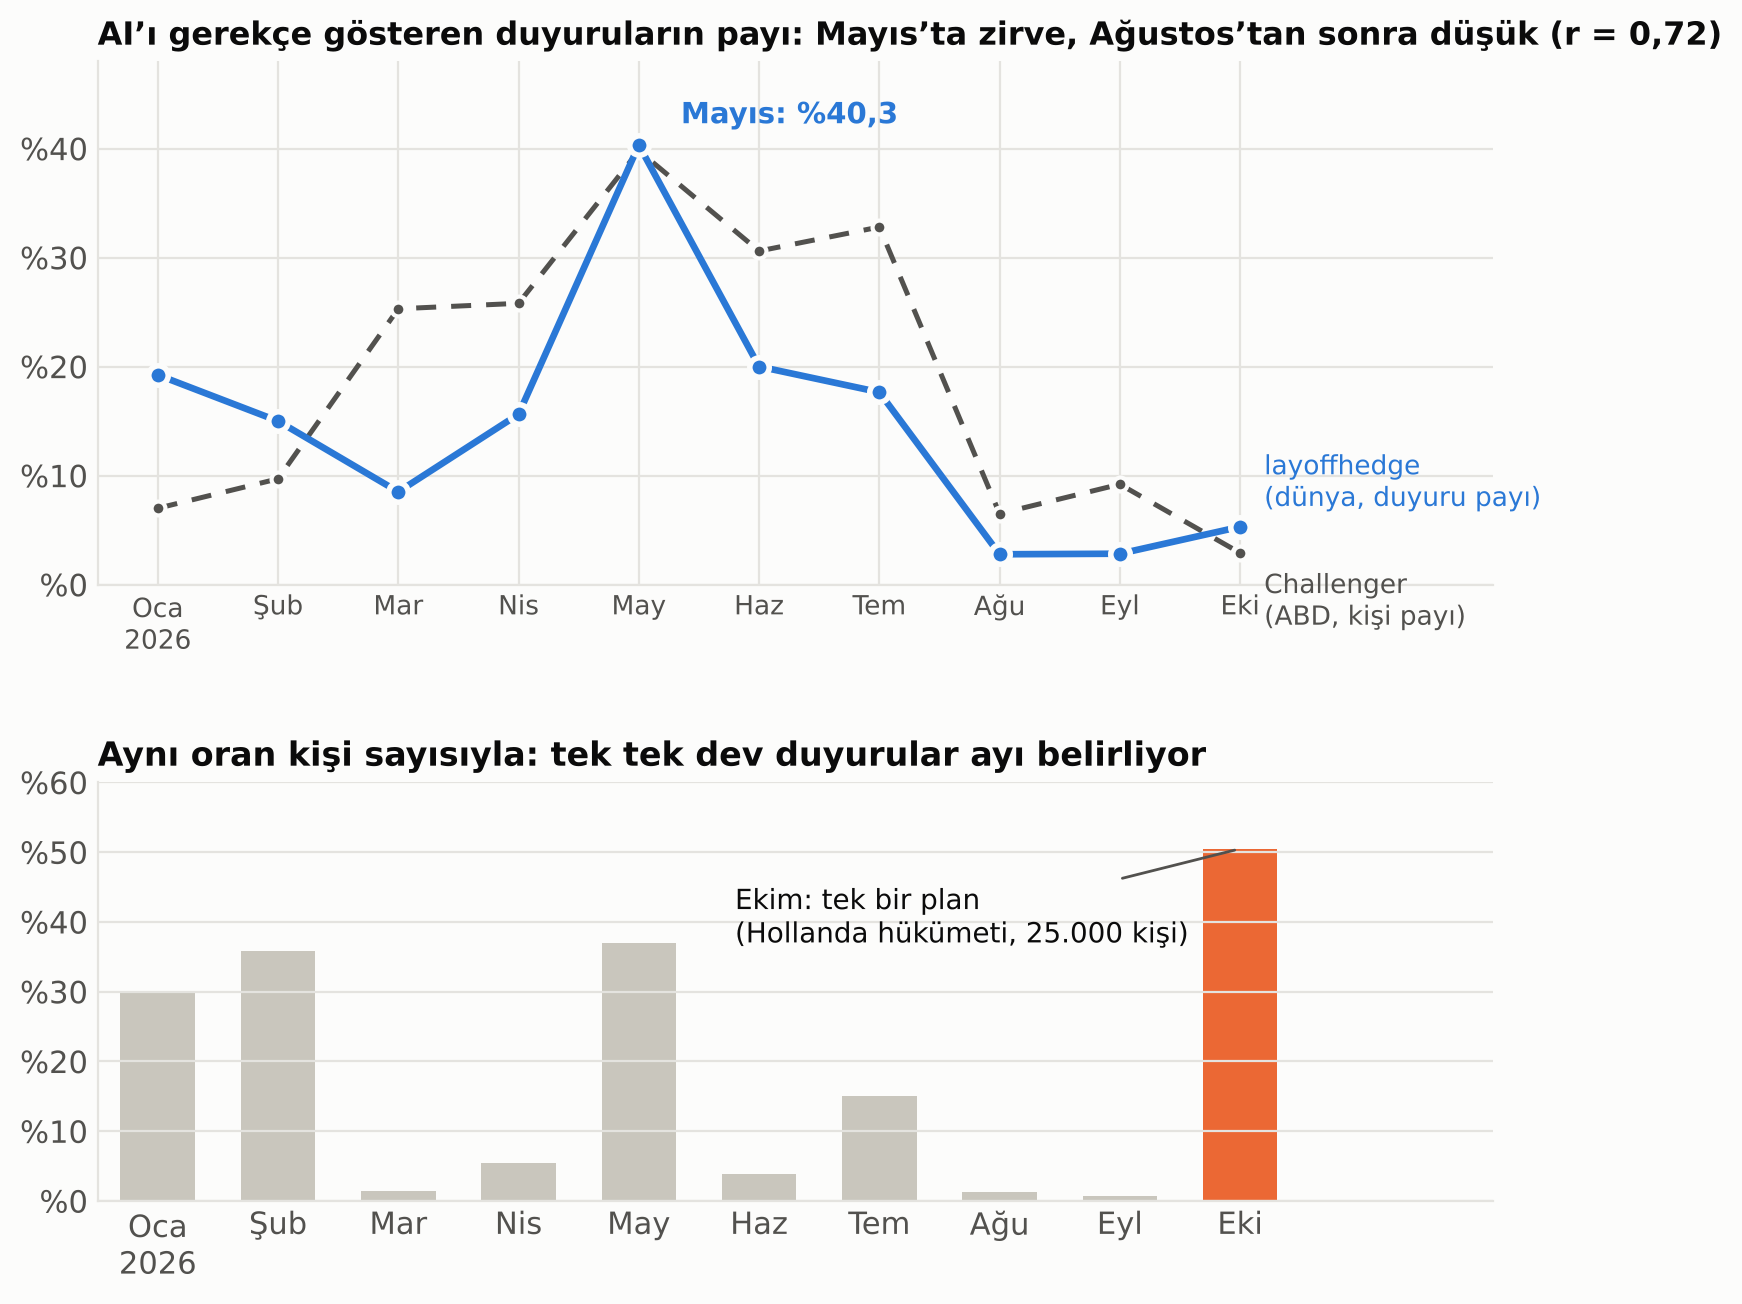

In [4]:
aylar = [f"2026-{i:02d}" for i in range(1, 11)]  # Kasım eksik ay olduğu için dışarıda
g = m.groupby("month").agg(n=("company", "size"), ai=("is_ai_strict", "sum"), pp=("people_cut", "sum"))
g["sayi_payi"] = g["ai"] / g["n"] * 100
g["kisi_payi"] = dar.groupby("month")["people_cut"].sum().reindex(g.index).fillna(0) / g["pp"] * 100
g = g.loc[aylar]
ch = oku("challenger_ai_monthly.csv").set_index("month").loc[aylar, "ai_share_pct"]
r = np.corrcoef(g["sayi_payi"], ch)[0, 1]
print("\n[Grafik 2] aylık AI duyuru payı (dar):", dict(zip(aylar, g["sayi_payi"].round(1))))
print("           aylık AI kişi payı (dar):  ", dict(zip(aylar, g["kisi_payi"].round(1))))
print(f"           Challenger ile korelasyon: {r:.2f}")
x = np.arange(len(aylar))

fig, axes = plt.subplots(2, 1, figsize=(9, 7.4), sharex=True, gridspec_kw=dict(height_ratios=[1.25, 1], hspace=0.42))
ax = axes[0]
ax.plot(x, g["sayi_payi"], color=BLUE, lw=2.4, marker="o", ms=7, mec=SURFACE, mew=2, zorder=3)
ax.plot(x, ch.values, color=INK_2, lw=1.8, ls=(0, (4, 3)), marker="o", ms=5, mec=SURFACE, mew=1.5, zorder=2)
i_may = aylar.index("2026-05")
ax.annotate(f"Mayıs: %{y1(g['sayi_payi'].iloc[i_may])}", xy=(i_may, g["sayi_payi"].iloc[i_may]),
            xytext=(i_may + 0.35, g["sayi_payi"].iloc[i_may] + 2), color=BLUE, fontsize=10.5, fontweight="bold")
ax.text(len(x) - 1 + 0.2, g["sayi_payi"].iloc[-1] + 4, "layoffhedge\n(dünya, duyuru payı)", color=BLUE, fontsize=9.5, va="center")
ax.text(len(x) - 1 + 0.2, ch.values[-1] - 4.5, "Challenger\n(ABD, kişi payı)", color=INK_2, fontsize=9.5, va="center")
ax.set_ylim(0, 48); ax.yaxis.set_major_formatter(YUZDE)
r_txt = f"{r:.2f}".replace(".", ",")
ax.set_title(f"AI’ı gerekçe gösteren duyuruların payı: Mayıs’ta zirve, Ağustos’tan sonra düşük (r = {r_txt})", fontsize=11.5)
ax.tick_params(labelbottom=True)
ax.set_xticks(x); ax.set_xticklabels([ay_etiket(a).split("\n")[0] for a in aylar], fontsize=9.5)
ax2 = axes[1]
ax2.bar(x, g["kisi_payi"], color=LIGHT, width=0.62)
i_eki = aylar.index("2026-10")
ax2.bar(i_eki, g["kisi_payi"].iloc[i_eki], color=ORANGE, width=0.62)
ax2.annotate("Ekim: tek bir plan\n(Hollanda hükümeti, 25.000 kişi)", xy=(i_eki, g["kisi_payi"].iloc[i_eki]),
             xytext=(i_eki - 4.2, g["kisi_payi"].iloc[i_eki] - 10), color=INK, fontsize=10, va="center",
             arrowprops=dict(arrowstyle="-", color=INK_2, lw=1))
ax2.set_ylim(0, 60); ax2.yaxis.set_major_formatter(YUZDE)
ax2.set_title("Aynı oran kişi sayısıyla: tek tek dev duyurular ayı belirliyor", fontsize=12)
ax2.grid(axis="x", visible=False)
ax2.set_xticks(x); ax2.set_xticklabels([ay_etiket(a) for a in aylar])
ax.set_xlim(-0.5, len(x) - 0.5 + 1.6)
save(fig, "02_aylik_ai_payi.png")


## 3. İki taraf: işten çıkarma gerekçesi ve iş ilanları
Indeed Hiring Lab AI Tracker (CC BY 4.0). Kanada, Ontario düzenlemesi nedeniyle karşılaştırılabilir değil. Neden-sonuç iddiası değildir.


[Grafik 3] Indeed AI ilan payı: ABD 3.6 → 7.2 | İngiltere 4.9 → 9.8
           Eylül 2025 → Eylül 2026 artan ülke (Kanada hariç): 8/8


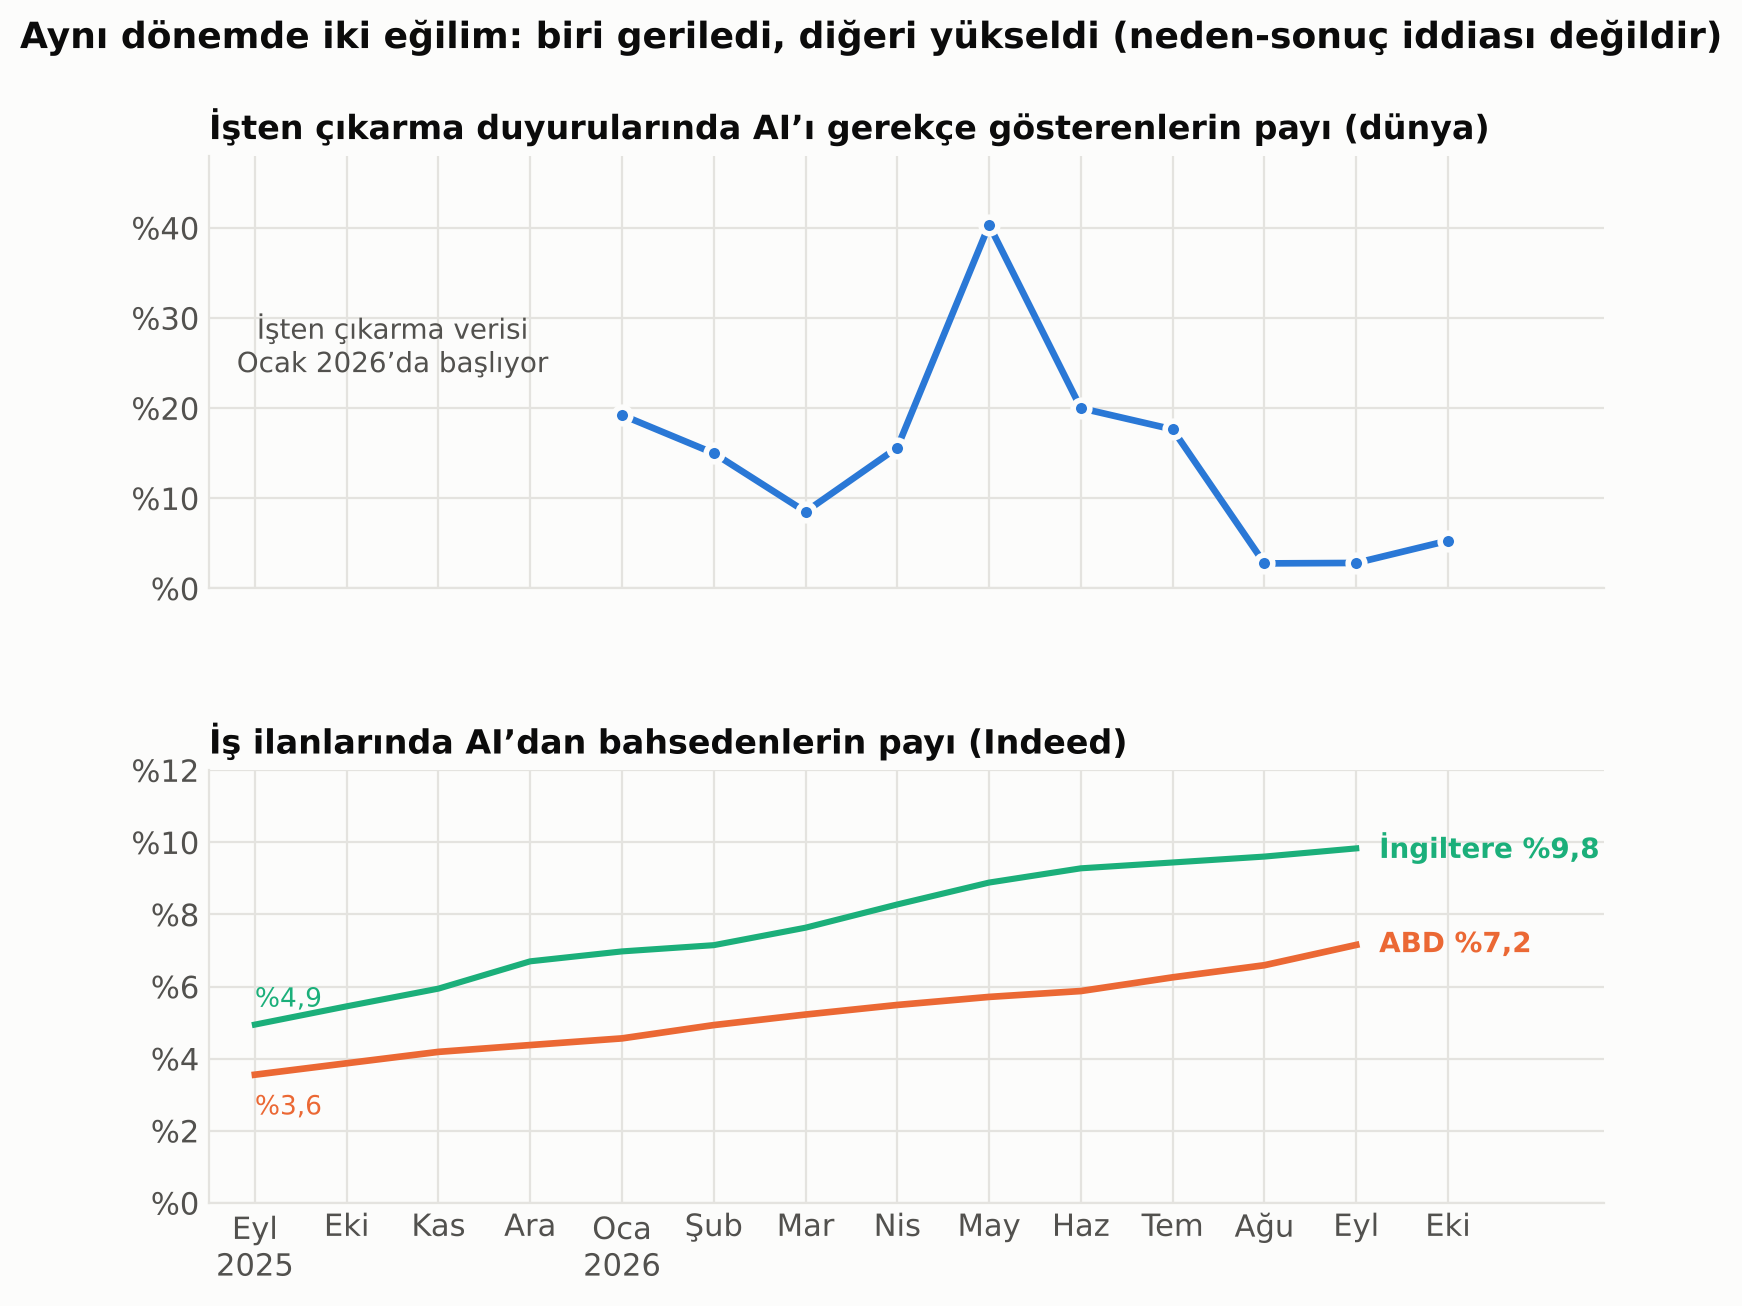


Görseller: gorseller


In [5]:
a = oku("ai_posting_monthly.csv")
aralik = pd.period_range("2025-09", "2026-10", freq="M").astype(str).tolist()
us = a[a.country_code == "US"].set_index("month")["ai_share_pct"].reindex(aralik)
gb = a[a.country_code == "GB"].set_index("month")["ai_share_pct"].reindex(aralik)
print(f"\n[Grafik 3] Indeed AI ilan payı: ABD {us['2025-09']:.1f} → {us['2026-09']:.1f} | "
      f"İngiltere {gb['2025-09']:.1f} → {gb['2026-09']:.1f}")
artan = (a[a.month == "2026-09"].set_index("country_code")["ai_share_pct"] >
         a[a.month == "2025-09"].set_index("country_code")["ai_share_pct"])
artan = artan.drop("CA")  # Kanada: Ontario düzenlemesi nedeniyle karşılaştırılabilir değil
print(f"           Eylül 2025 → Eylül 2026 artan ülke (Kanada hariç): {int(artan.sum())}/{len(artan)}")
xa = np.arange(len(aralik))
lay = g["sayi_payi"].reindex(aralik)

fig, axes = plt.subplots(2, 1, figsize=(9, 6.8), sharex=True, gridspec_kw=dict(hspace=0.42))
ax = axes[0]
ax.plot(xa, lay.values, color=BLUE, lw=2.4, marker="o", ms=6, mec=SURFACE, mew=2)
ax.set_ylim(0, 48); ax.yaxis.set_major_formatter(YUZDE)
ax.set_title("İşten çıkarma duyurularında AI’ı gerekçe gösterenlerin payı (dünya)", fontsize=12)
ax.text(1.5, 24, "İşten çıkarma verisi\nOcak 2026’da başlıyor", color=INK_2, fontsize=10, ha="center")
ax2 = axes[1]
ax2.plot(xa, gb.values, color=AQUA, lw=2.2)
ax2.plot(xa, us.values, color=ORANGE, lw=2.4)
ax2.text(xa[aralik.index("2026-09")] + 0.25, gb["2026-09"], f"İngiltere %{y1(gb['2026-09'])}", color=AQUA, fontsize=10, va="center", fontweight="bold")
ax2.text(xa[aralik.index("2026-09")] + 0.25, us["2026-09"], f"ABD %{y1(us['2026-09'])}", color=ORANGE, fontsize=10, va="center", fontweight="bold")
ax2.text(0, us["2025-09"] - 1.1, f"%{y1(us['2025-09'])}", color=ORANGE, fontsize=9.5)
ax2.text(0, gb["2025-09"] + 0.5, f"%{y1(gb['2025-09'])}", color=AQUA, fontsize=9.5)
ax2.set_ylim(0, 12); ax2.yaxis.set_major_formatter(YUZDE)
ax2.set_title("İş ilanlarında AI’dan bahsedenlerin payı (Indeed)", fontsize=12)
ax2.set_xticks(xa); ax2.set_xticklabels([ay_etiket(v) for v in aralik])
ax2.set_xlim(-0.5, len(xa) - 0.5 + 1.2)
fig.suptitle("Aynı dönemde iki eğilim: biri geriledi, diğeri yükseldi (neden-sonuç iddiası değildir)",
             x=0.02, ha="left", fontsize=13, fontweight="bold", color=INK)
save(fig, "03_iki_taraf.png")

print("\nGörseller:", OUT)
